In [1]:
from pathlib import Path
from collections import defaultdict

# ============================================================
# DATASET PATH
# ============================================================

DATASET_DIR = Path(
    r"C:\Users\ASUS\My_Learning\medical mlops project\dataset"
)

TRAINING_DIR = DATASET_DIR / "Training"
TESTING_DIR = DATASET_DIR / "Testing"

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


# ============================================================
# FUNCTION TO COUNT IMAGES RECURSIVELY
# ============================================================

def count_images_recursive(folder):

    counts = defaultdict(int)

    if not folder.exists():
        print(f"Folder not found: {folder}")
        return counts

    # rglob searches ALL nested folders
    for file in folder.rglob("*"):

        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:

            # Get folder relative to Training/Testing
            relative_path = file.parent.relative_to(folder)

            # Class/folder name
            class_name = str(relative_path)

            counts[class_name] += 1

    return counts


# ============================================================
# COUNT TRAINING DATA
# ============================================================

training_counts = count_images_recursive(TRAINING_DIR)


# ============================================================
# COUNT TESTING DATA
# ============================================================

testing_counts = count_images_recursive(TESTING_DIR)


# ============================================================
# DISPLAY TRAINING COUNTS
# ============================================================

print("\n")
print("=" * 80)
print("TRAINING DATASET")
print("=" * 80)

training_total = 0

for folder, count in sorted(training_counts.items()):

    print(f"{folder:<50} : {count:>6} images")

    training_total += count

print("-" * 80)
print(f"{'TOTAL TRAINING IMAGES':<50} : {training_total:>6}")


# ============================================================
# DISPLAY TESTING COUNTS
# ============================================================

print("\n")
print("=" * 80)
print("TESTING DATASET")
print("=" * 80)

testing_total = 0

for folder, count in sorted(testing_counts.items()):

    print(f"{folder:<50} : {count:>6} images")

    testing_total += count

print("-" * 80)
print(f"{'TOTAL TESTING IMAGES':<50} : {testing_total:>6}")


# ============================================================
# OVERALL TOTAL
# ============================================================

print("\n")
print("=" * 80)
print("OVERALL DATASET")
print("=" * 80)

print(f"Training images : {training_total}")
print(f"Testing images  : {testing_total}")
print(f"Total images    : {training_total + testing_total}")

print("=" * 80)



TRAINING DATASET
glioma                                             :   1400 images
meningioma                                         :   1400 images
notumor                                            :   1400 images
pituitary                                          :   1400 images
--------------------------------------------------------------------------------
TOTAL TRAINING IMAGES                              :   5600


TESTING DATASET
glioma                                             :    400 images
meningioma                                         :    400 images
notumor                                            :    400 images
pituitary                                          :    400 images
--------------------------------------------------------------------------------
TOTAL TESTING IMAGES                               :   1600


OVERALL DATASET
Training images : 5600
Testing images  : 1600
Total images    : 7200


In [2]:
from pathlib import Path
import shutil
import random

# ============================================================
# CONFIGURATION
# ============================================================

DATASET_DIR = Path(
    r"C:\Users\ASUS\My_Learning\medical mlops project\dataset"
)

SOURCE_TRAINING = DATASET_DIR / "Training"
SOURCE_TESTING = DATASET_DIR / "Testing"

OUTPUT_DIR = DATASET_DIR / "split_dataset"

TRAIN_DIR = OUTPUT_DIR / "train"
VAL_DIR = OUTPUT_DIR / "validation"
TEST_DIR = OUTPUT_DIR / "test"

# 85% of the original Training folder → Train
# 15% of the original Training folder → Validation
VAL_RATIO = 0.15

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


# ============================================================
# CHECK SOURCE FOLDERS
# ============================================================

if not SOURCE_TRAINING.exists():
    raise FileNotFoundError(
        f"Training folder not found:\n{SOURCE_TRAINING}"
    )

if not SOURCE_TESTING.exists():
    raise FileNotFoundError(
        f"Testing folder not found:\n{SOURCE_TESTING}"
    )


# ============================================================
# FIND CLASS FOLDERS
# ============================================================

classes = sorted([
    folder.name
    for folder in SOURCE_TRAINING.iterdir()
    if folder.is_dir()
])

if not classes:
    raise ValueError(
        "No class folders found inside Training."
    )

print("=" * 80)
print("CLASSES FOUND")
print("=" * 80)

for cls in classes:
    print(f"  {cls}")

print()


# ============================================================
# CREATE OUTPUT DIRECTORIES
# ============================================================

for cls in classes:

    (TRAIN_DIR / cls).mkdir(
        parents=True,
        exist_ok=True
    )

    (VAL_DIR / cls).mkdir(
        parents=True,
        exist_ok=True
    )

    (TEST_DIR / cls).mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# SPLIT TRAINING DATA
# ============================================================

print("=" * 80)
print("SPLITTING TRAINING DATA")
print("=" * 80)

total_train = 0
total_val = 0

for cls in classes:

    source_class_dir = SOURCE_TRAINING / cls

    # Find images
    images = [
        file
        for file in source_class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    # Shuffle images
    random.shuffle(images)

    total_images = len(images)

    # Calculate validation count
    val_count = int(total_images * VAL_RATIO)

    # Split
    val_images = images[:val_count]
    train_images = images[val_count:]

    # --------------------------------------------------------
    # Copy TRAIN images
    # --------------------------------------------------------

    for image_path in train_images:

        destination = TRAIN_DIR / cls / image_path.name

        shutil.copy2(
            image_path,
            destination
        )

    # --------------------------------------------------------
    # Copy VALIDATION images
    # --------------------------------------------------------

    for image_path in val_images:

        destination = VAL_DIR / cls / image_path.name

        shutil.copy2(
            image_path,
            destination
        )

    total_train += len(train_images)
    total_val += len(val_images)

    print(
        f"{cls:<20} "
        f"Original: {total_images:>5} | "
        f"Train: {len(train_images):>5} | "
        f"Validation: {len(val_images):>5}"
    )


# ============================================================
# COPY EXISTING TESTING DATA
# ============================================================

print()
print("=" * 80)
print("COPYING TEST DATA")
print("=" * 80)

total_test = 0

for cls in classes:

    source_class_dir = SOURCE_TESTING / cls

    if not source_class_dir.exists():

        print(
            f"WARNING: Testing class folder not found: {cls}"
        )

        continue

    images = [
        file
        for file in source_class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in images:

        destination = TEST_DIR / cls / image_path.name

        shutil.copy2(
            image_path,
            destination
        )

    total_test += len(images)

    print(
        f"{cls:<20} : {len(images):>5} images"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 80)
print("DATASET SPLIT COMPLETED")
print("=" * 80)

print(
    f"Training images     : {total_train}"
)

print(
    f"Validation images   : {total_val}"
)

print(
    f"Testing images      : {total_test}"
)

print(
    f"Total images        : "
    f"{total_train + total_val + total_test}"
)

print()
print("=" * 80)
print("EXPECTED COUNTS")
print("=" * 80)

print("Training     : 4,760")
print("Validation   :   840")
print("Testing      : 1,600")
print("Total        : 7,200")

print()
print("=" * 80)
print("OUTPUT STRUCTURE")
print("=" * 80)

print(f"""
{OUTPUT_DIR}
│
├── train/
│   ├── glioma/
│   ├── meningioma/
│   ├── notumor/
│   └── pituitary/
│
├── validation/
│   ├── glioma/
│   ├── meningioma/
│   ├── notumor/
│   └── pituitary/
│
└── test/
    ├── glioma/
    ├── meningioma/
    ├── notumor/
    └── pituitary/
""")

print("=" * 80)
print("IMPORTANT")
print("=" * 80)

print("""
Original Training and Testing folders were NOT modified.
All files were COPIED into split_dataset.

Training     = 85% of original Training
Validation   = 15% of original Training
Testing      = Original Testing dataset
""")

print("Dataset is ready for model training!")

CLASSES FOUND
  glioma
  meningioma
  notumor
  pituitary

SPLITTING TRAINING DATA
glioma               Original:  1400 | Train:  1190 | Validation:   210
meningioma           Original:  1400 | Train:  1190 | Validation:   210
notumor              Original:  1400 | Train:  1190 | Validation:   210
pituitary            Original:  1400 | Train:  1190 | Validation:   210

COPYING TEST DATA
glioma               :   400 images
meningioma           :   400 images
notumor              :   400 images
pituitary            :   400 images

DATASET SPLIT COMPLETED
Training images     : 4760
Validation images   : 840
Testing images      : 1600
Total images        : 7200

EXPECTED COUNTS
Training     : 4,760
Validation   :   840
Testing      : 1,600
Total        : 7,200

OUTPUT STRUCTURE

C:\Users\ASUS\My_Learning\medical mlops project\dataset\split_dataset
│
├── train/
│   ├── glioma/
│   ├── meningioma/
│   ├── notumor/
│   └── pituitary/
│
├── validation/
│   ├── glioma/
│   ├── meningioma/
│   ├

CHECKING DATASET
✓ Found: C:\Users\ASUS\My_Learning\medical mlops project\dataset\split_dataset\train
✓ Found: C:\Users\ASUS\My_Learning\medical mlops project\dataset\split_dataset\validation
✓ Found: C:\Users\ASUS\My_Learning\medical mlops project\dataset\split_dataset\test


CHECKING CLASS FOLDERS

TRAIN
  ✓ glioma
  ✓ meningioma
  ✓ notumor
  ✓ pituitary

VALIDATION
  ✓ glioma
  ✓ meningioma
  ✓ notumor
  ✓ pituitary

TEST
  ✓ glioma
  ✓ meningioma
  ✓ notumor
  ✓ pituitary
Found 4760 images belonging to 4 classes.
Found 840 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


CLASS MAPPING
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


DATASET STATISTICS
Number of classes       : 4
Image size              : (224, 224)
Batch size              : 32

Training images         : 4760
Validation images       : 840
Testing images          : 1600

Training batches        : 149
Validation batches      : 27
Testing batches         : 50


CLASS DISTRIBUTIO

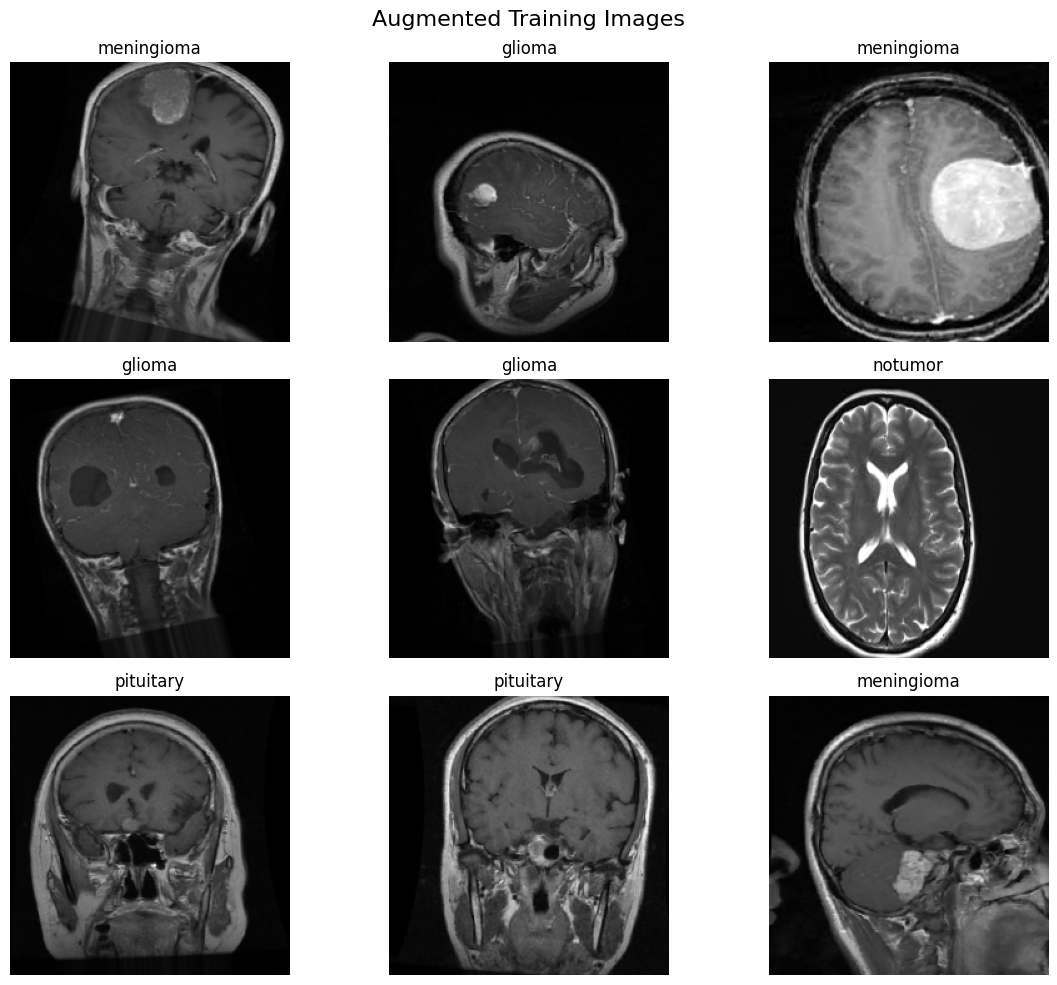

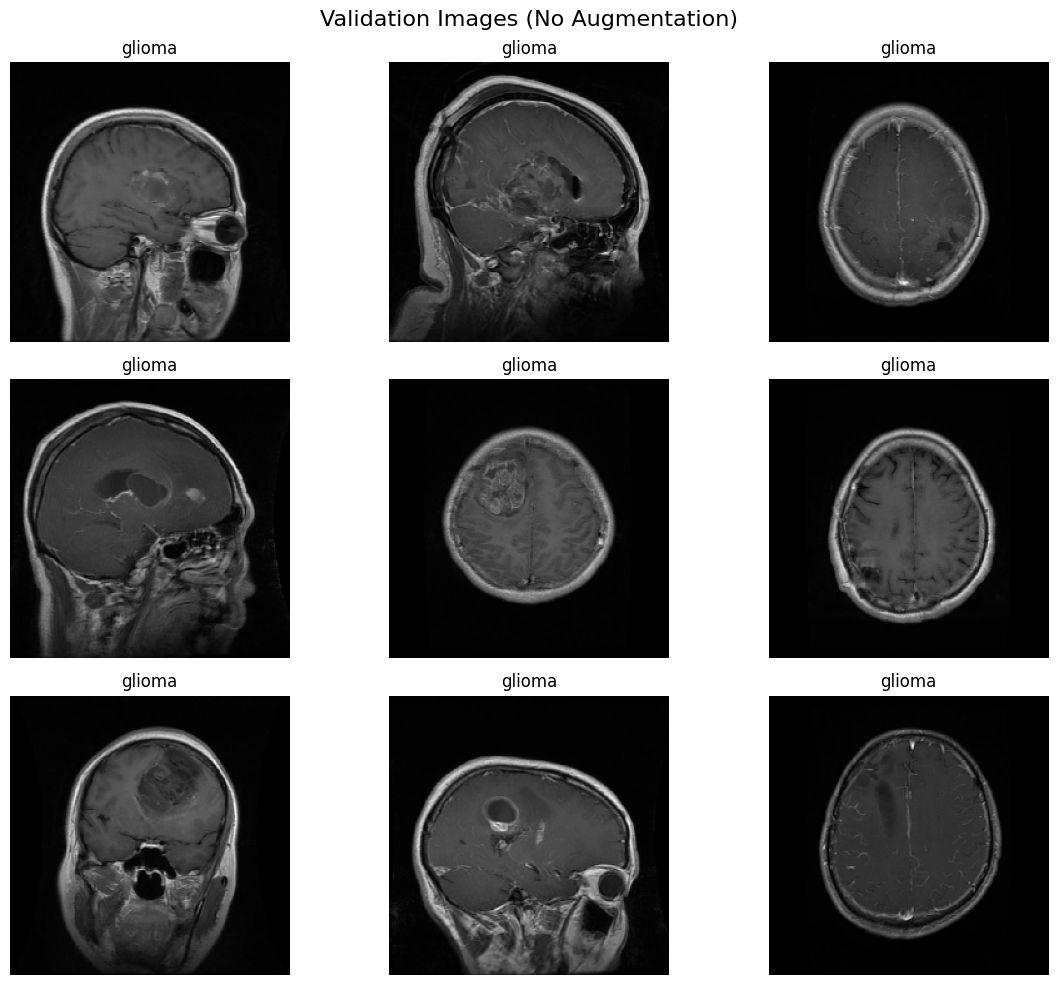



PREPROCESSING AND AUGMENTATION READY

Training:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Rotation             : ±15 degrees
    - Width shift          : 10%
    - Height shift         : 10%
    - Zoom                 : 10%
    - Shear               : 5%
    - Horizontal flip      : Enabled
    - Brightness           : 90% - 110%

Validation:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Augmentation         : None

Testing:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Augmentation         : None

Generators created successfully.

Available variables for model training:
  train_generator
  validation_generator
  test_generator

Ready for model training.


In [3]:
# ============================================================
# BRAIN TUMOR MRI
# PREPROCESSING + DATA AUGMENTATION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_DIR = r"C:\Users\ASUS\My_Learning\medical mlops project\dataset\split_dataset"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR   = os.path.join(DATASET_DIR, "validation")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

# Image configuration
IMG_SIZE = (224, 224)
IMAGE_SIZE = (224, 224, 3)

BATCH_SIZE = 32

# Reproducibility
SEED = 42

# Classes
CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

NUM_CLASSES = len(CLASS_NAMES)


# ============================================================
# 2. CHECK DATASET DIRECTORIES
# ============================================================

print("=" * 80)
print("CHECKING DATASET")
print("=" * 80)

for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:

    if not os.path.exists(directory):

        raise FileNotFoundError(
            f"\nDataset folder not found:\n{directory}"
        )

    print(f"✓ Found: {directory}")


# ============================================================
# 3. CHECK CLASS DIRECTORIES
# ============================================================

print("\n")
print("=" * 80)
print("CHECKING CLASS FOLDERS")
print("=" * 80)

for directory_name, directory in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR)
]:

    print(f"\n{directory_name}")

    for class_name in CLASS_NAMES:

        class_path = os.path.join(
            directory,
            class_name
        )

        if not os.path.exists(class_path):

            raise FileNotFoundError(
                f"Missing class folder:\n{class_path}"
            )

        print(f"  ✓ {class_name}")


# ============================================================
# 4. DATA AUGMENTATION
# ============================================================
#
# IMPORTANT:
# Augmentation is applied ONLY to TRAINING images.
#
# Validation and Testing must remain untouched so that they
# represent real unseen data.
#
# We avoid vertical flipping because it can produce
# anatomically unrealistic MRI images.
# ============================================================

train_datagen = ImageDataGenerator(

    # Pixel normalization
    rescale=1.0 / 255.0,

    # Rotation
    rotation_range=15,

    # Small translations
    width_shift_range=0.10,
    height_shift_range=0.10,

    # Zoom
    zoom_range=0.10,

    # Shear
    shear_range=0.05,

    # Horizontal flip
    horizontal_flip=True,

    # Small brightness variation
    brightness_range=[0.90, 1.10],

    # Fill empty areas created by transformations
    fill_mode="nearest"
)


# ============================================================
# 5. VALIDATION PREPROCESSING
# ============================================================
#
# NO augmentation.
# Only resize + normalization.
# ============================================================

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)


# ============================================================
# 6. TEST PREPROCESSING
# ============================================================
#
# NO augmentation.
# Only resize + normalization.
# ============================================================

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)


# ============================================================
# 7. CREATE TRAINING GENERATOR
# ============================================================

train_generator = train_datagen.flow_from_directory(

    TRAIN_DIR,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    classes=CLASS_NAMES,

    shuffle=True,

    seed=SEED
)


# ============================================================
# 8. CREATE VALIDATION GENERATOR
# ============================================================

validation_generator = val_datagen.flow_from_directory(

    VAL_DIR,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    classes=CLASS_NAMES,

    shuffle=False
)


# ============================================================
# 9. CREATE TEST GENERATOR
# ============================================================

test_generator = test_datagen.flow_from_directory(

    TEST_DIR,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    classes=CLASS_NAMES,

    shuffle=False
)


# ============================================================
# 10. DISPLAY CLASS INDICES
# ============================================================

print("\n")
print("=" * 80)
print("CLASS MAPPING")
print("=" * 80)

print(train_generator.class_indices)


# ============================================================
# 11. DATASET STATISTICS
# ============================================================

print("\n")
print("=" * 80)
print("DATASET STATISTICS")
print("=" * 80)

print(f"Number of classes       : {NUM_CLASSES}")
print(f"Image size              : {IMG_SIZE}")
print(f"Batch size              : {BATCH_SIZE}")

print()
print(f"Training images         : {train_generator.samples}")
print(f"Validation images       : {validation_generator.samples}")
print(f"Testing images          : {test_generator.samples}")

print()
print(f"Training batches        : {len(train_generator)}")
print(f"Validation batches      : {len(validation_generator)}")
print(f"Testing batches         : {len(test_generator)}")


# ============================================================
# 12. EXPECTED CLASS DISTRIBUTION
# ============================================================

print("\n")
print("=" * 80)
print("CLASS DISTRIBUTION")
print("=" * 80)

for class_name in CLASS_NAMES:

    train_count = len(
        os.listdir(
            os.path.join(TRAIN_DIR, class_name)
        )
    )

    val_count = len(
        os.listdir(
            os.path.join(VAL_DIR, class_name)
        )
    )

    test_count = len(
        os.listdir(
            os.path.join(TEST_DIR, class_name)
        )
    )

    print(
        f"{class_name:<15} "
        f"Train: {train_count:>5} | "
        f"Val: {val_count:>5} | "
        f"Test: {test_count:>5}"
    )


# ============================================================
# 13. LOAD ONE BATCH
# ============================================================

images, labels = next(train_generator)

print("\n")
print("=" * 80)
print("BATCH INFORMATION")
print("=" * 80)

print(f"Image batch shape : {images.shape}")
print(f"Label batch shape : {labels.shape}")

print(
    f"Pixel minimum     : {images.min():.4f}"
)

print(
    f"Pixel maximum     : {images.max():.4f}"
)


# ============================================================
# 14. DISPLAY AUGMENTED IMAGES
# ============================================================

print("\nDisplaying augmented training images...")

plt.figure(figsize=(12, 10))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i])

    class_index = np.argmax(labels[i])

    class_name = CLASS_NAMES[class_index]

    plt.title(class_name)

    plt.axis("off")

plt.suptitle(
    "Augmented Training Images",
    fontsize=16
)

plt.tight_layout()

plt.show()


# ============================================================
# 15. DISPLAY VALIDATION IMAGES
# ============================================================

val_images, val_labels = next(validation_generator)

plt.figure(figsize=(12, 10))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(val_images[i])

    class_index = np.argmax(val_labels[i])

    class_name = CLASS_NAMES[class_index]

    plt.title(class_name)

    plt.axis("off")

plt.suptitle(
    "Validation Images (No Augmentation)",
    fontsize=16
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. RESET GENERATORS
# ============================================================

train_generator.reset()
validation_generator.reset()
test_generator.reset()


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("PREPROCESSING AND AUGMENTATION READY")
print("=" * 80)

print("""
Training:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Rotation             : ±15 degrees
    - Width shift          : 10%
    - Height shift         : 10%
    - Zoom                 : 10%
    - Shear               : 5%
    - Horizontal flip      : Enabled
    - Brightness           : 90% - 110%

Validation:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Augmentation         : None

Testing:
    - Resize               : 224 x 224
    - Normalize            : /255
    - Augmentation         : None
""")

print("Generators created successfully.")

print("\nAvailable variables for model training:")
print("  train_generator")
print("  validation_generator")
print("  test_generator")

print("\nReady for model training.")

HARDWARE
No GPU detected. Using CPU.


DATASET
Training images   : 4760
Validation images : 840
Testing images    : 1600
Classes           : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


BUILDING DENSENET121


Model: "DenseNet121_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,300,932 (27.85 MB)

 Trainable params: 263,428 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)



STAGE 1 — TRANSFER LEARNING
Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3493 - loss: 1.7111
Epoch 1: val_accuracy improved from None to 0.78214, saving model to C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - accuracy: 0.4742 - loss: 1.3074 - val_accuracy: 0.7821 - val_loss: 0.6183 - learning_rate: 1.0000e-04
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6709 - loss: 0.8156
Epoch 2: val_accuracy improved from 0.78214 to 0.80595, saving model to C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 217s 1s/step - accuracy: 0.6897 - loss: 0.7818 - val_accuracy: 0.8060 - val_loss: 0.5103 - learning_rate: 1.0000e-04
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7438 - loss: 0.6854
Epoch 3: val_accuracy improved from 0.80595 to 0.82024, saving model to C:\Users\ASUS\My_Learning\medi

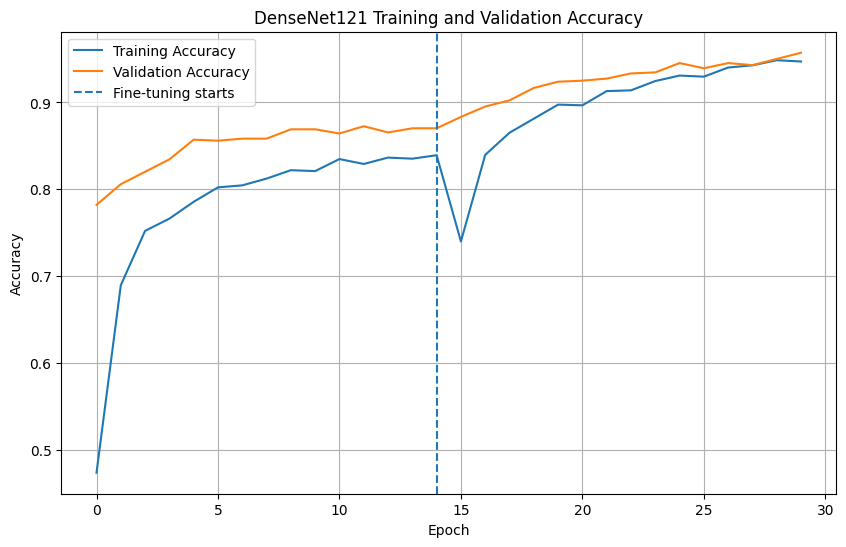

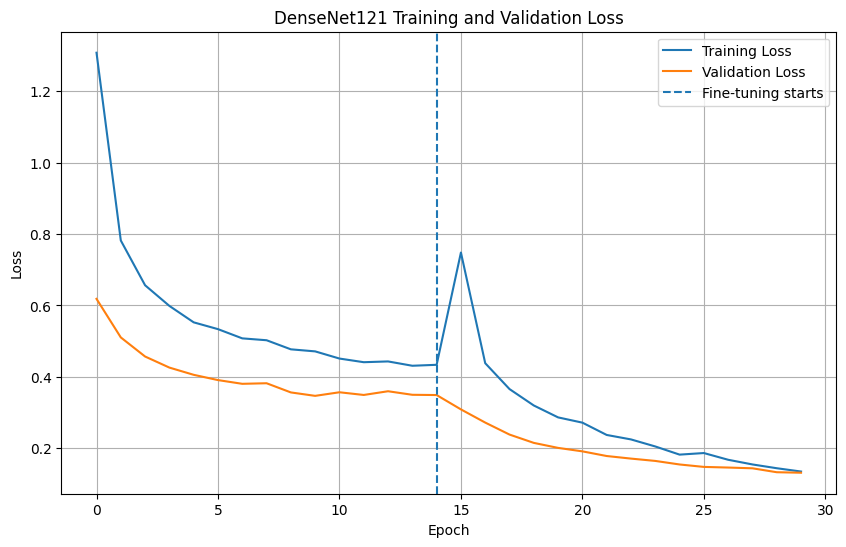



LOADING BEST MODEL
Best model loaded from:
C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_best.keras


FINAL TEST EVALUATION
50/50 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.9069 - loss: 0.3707


Test Loss     : 0.3707
Test Accuracy : 0.9069
Test Accuracy : 90.69%


GENERATING TEST PREDICTIONS
50/50 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step


CLASSIFICATION ACCURACY
Accuracy: 0.9069
Accuracy: 90.69%


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9711    0.7550    0.8495       400
  meningioma     0.8716    0.8825    0.8770       400
     notumor     0.9172    0.9975    0.9557       400
   pituitary     0.8842    0.9925    0.9352       400

    accuracy                         0.9069      1600
   macro avg     0.9110    0.9069    0.9044      1600
weighted avg     0.9110    0.9069    0.9044      1600



CONFUSION MATRIX
[[302  49  30  19]
 [  8 353   6  33]
 [  1   0 399   0]
 [  0   3   0 397]]


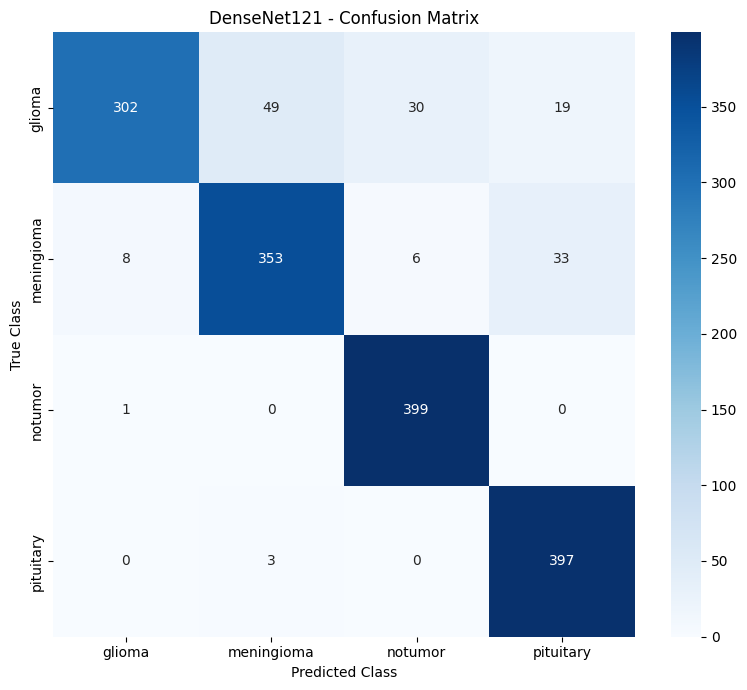



PER-CLASS ACCURACY
glioma          : 75.50%
meningioma      : 88.25%
notumor         : 99.75%
pituitary       : 99.25%


MODEL SAVED
Final model:
C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras
Best checkpoint:
C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_best.keras


FINAL RESULTS
Test Loss     : 0.3707
Test Accuracy : 90.69%

Classes:
  0 → glioma
  1 → meningioma
  2 → notumor
  3 → pituitary

Model architecture : DenseNet121
Transfer learning  : ImageNet
Fine-tuning         : Enabled
Input size          : 224 × 224 × 3
Number of classes   : 4


In [5]:
# ============================================================
# DENSENET121 - BRAIN TUMOR CLASSIFICATION
# COMPLETE TRAINING + EVALUATION PIPELINE
# ============================================================

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import seaborn as sns


# ============================================================
# 1. CONFIGURATION
# ============================================================

IMG_SIZE = (224, 224)

NUM_CLASSES = 4

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

BATCH_SIZE = 32

# Stage 1: Frozen DenseNet
INITIAL_EPOCHS = 15

# Stage 2: Fine-tuning
FINE_TUNE_EPOCHS = 15

INITIAL_LR = 1e-4
FINE_TUNE_LR = 1e-5

MODEL_DIR = r"C:\Users\ASUS\My_Learning\medical mlops project\models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "densenet121_brain_tumor_best.keras"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "densenet121_brain_tumor_final.keras"
)

HISTORY_PATH = os.path.join(
    MODEL_DIR,
    "densenet121_training_history.json"
)


# ============================================================
# 2. CHECK GPU
# ============================================================

print("=" * 80)
print("HARDWARE")
print("=" * 80)

gpus = tf.config.list_physical_devices("GPU")

if gpus:

    print("GPU detected:")
    for gpu in gpus:
        print(gpu)

    for gpu in gpus:

        try:
            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )
        except:
            pass

else:

    print("No GPU detected. Using CPU.")


# ============================================================
# 3. CHECK GENERATORS
# ============================================================

print("\n")
print("=" * 80)
print("DATASET")
print("=" * 80)

print(
    f"Training images   : {train_generator.samples}"
)

print(
    f"Validation images : {validation_generator.samples}"
)

print(
    f"Testing images    : {test_generator.samples}"
)

print(
    f"Classes           : {train_generator.class_indices}"
)


# ============================================================
# 4. BUILD DENSENET121
# ============================================================

print("\n")
print("=" * 80)
print("BUILDING DENSENET121")
print("=" * 80)

base_model = DenseNet121(

    weights="imagenet",

    include_top=False,

    input_shape=(
        IMG_SIZE[0],
        IMG_SIZE[1],
        3
    )
)


# Freeze pretrained layers initially
base_model.trainable = False


# ============================================================
# CLASSIFICATION HEAD
# ============================================================

inputs = Input(
    shape=(
        IMG_SIZE[0],
        IMG_SIZE[1],
        3
    )
)

x = base_model(
    inputs,
    training=False
)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.30)(x)

x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(0.30)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)


model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_BrainTumor"
)


# ============================================================
# 5. COMPILE MODEL
# ============================================================

model.compile(

    optimizer=Adam(
        learning_rate=INITIAL_LR
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


# ============================================================
# 6. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 7. CALLBACKS
# ============================================================

checkpoint = ModelCheckpoint(

    BEST_MODEL_PATH,

    monitor="val_accuracy",

    mode="max",

    save_best_only=True,

    verbose=1
)


early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=2,

    min_lr=1e-7,

    verbose=1
)


callbacks = [

    checkpoint,

    early_stopping,

    reduce_lr

]


# ============================================================
# 8. STAGE 1 — TRAIN CLASSIFICATION HEAD
# ============================================================

print("\n")
print("=" * 80)
print("STAGE 1 — TRANSFER LEARNING")
print("=" * 80)

history_initial = model.fit(

    train_generator,

    epochs=INITIAL_EPOCHS,

    validation_data=validation_generator,

    callbacks=callbacks,

    verbose=1
)


# ============================================================
# 9. STAGE 2 — FINE-TUNING
# ============================================================

print("\n")
print("=" * 80)
print("STAGE 2 — FINE-TUNING DENSENET121")
print("=" * 80)


# Unfreeze DenseNet
base_model.trainable = True


# Freeze early layers
# Train only the later layers
fine_tune_from = int(
    len(base_model.layers) * 0.70
)

for layer in base_model.layers[:fine_tune_from]:

    layer.trainable = False


print(
    f"Total DenseNet layers : {len(base_model.layers)}"
)

print(
    f"Fine-tuning from layer: {fine_tune_from}"
)


# Recompile with smaller learning rate
model.compile(

    optimizer=Adam(
        learning_rate=FINE_TUNE_LR
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


history_fine = model.fit(

    train_generator,

    epochs=FINE_TUNE_EPOCHS,

    validation_data=validation_generator,

    callbacks=callbacks,

    verbose=1
)


# ============================================================
# 10. COMBINE TRAINING HISTORY
# ============================================================

initial_acc = history_initial.history["accuracy"]

initial_val_acc = history_initial.history["val_accuracy"]

initial_loss = history_initial.history["loss"]

initial_val_loss = history_initial.history["val_loss"]


fine_acc = history_fine.history["accuracy"]

fine_val_acc = history_fine.history["val_accuracy"]

fine_loss = history_fine.history["loss"]

fine_val_loss = history_fine.history["val_loss"]


all_acc = initial_acc + fine_acc

all_val_acc = initial_val_acc + fine_val_acc

all_loss = initial_loss + fine_loss

all_val_loss = initial_val_loss + fine_val_loss


# ============================================================
# 11. SAVE TRAINING HISTORY
# ============================================================

history_data = {

    "accuracy": [
        float(x) for x in all_acc
    ],

    "val_accuracy": [
        float(x) for x in all_val_acc
    ],

    "loss": [
        float(x) for x in all_loss
    ],

    "val_loss": [
        float(x) for x in all_val_loss
    ]

}


with open(
    HISTORY_PATH,
    "w"
) as f:

    json.dump(
        history_data,
        f,
        indent=4
    )


# ============================================================
# 12. TRAINING ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    all_acc,
    label="Training Accuracy"
)

plt.plot(
    all_val_acc,
    label="Validation Accuracy"
)

plt.axvline(
    x=len(initial_acc) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title(
    "DenseNet121 Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 13. TRAINING LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    all_loss,
    label="Training Loss"
)

plt.plot(
    all_val_loss,
    label="Validation Loss"
)

plt.axvline(
    x=len(initial_loss) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title(
    "DenseNet121 Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 14. LOAD BEST MODEL
# ============================================================

print("\n")
print("=" * 80)
print("LOADING BEST MODEL")
print("=" * 80)

model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

print(
    f"Best model loaded from:\n{BEST_MODEL_PATH}"
)


# ============================================================
# 15. FINAL TEST EVALUATION
# ============================================================

print("\n")
print("=" * 80)
print("FINAL TEST EVALUATION")
print("=" * 80)

test_generator.reset()

test_loss, test_accuracy = model.evaluate(

    test_generator,

    verbose=1
)


print("\n")
print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)


# ============================================================
# 16. GENERATE PREDICTIONS
# ============================================================

print("\n")
print("=" * 80)
print("GENERATING TEST PREDICTIONS")
print("=" * 80)

test_generator.reset()

predictions = model.predict(

    test_generator,

    verbose=1
)


# Convert probabilities to class labels
predicted_classes = np.argmax(
    predictions,
    axis=1
)

# True labels
true_classes = test_generator.classes


# ============================================================
# 17. CLASSIFICATION ACCURACY
# ============================================================

accuracy = accuracy_score(
    true_classes,
    predicted_classes
)

print("\n")
print("=" * 80)
print("CLASSIFICATION ACCURACY")
print("=" * 80)

print(
    f"Accuracy: {accuracy:.4f}"
)

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)


# ============================================================
# 18. CLASSIFICATION REPORT
# ============================================================

print("\n")
print("=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

report = classification_report(

    true_classes,

    predicted_classes,

    target_names=CLASS_NAMES,

    digits=4
)

print(report)


# ============================================================
# 19. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    true_classes,

    predicted_classes
)


print("\n")
print("=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)


# ============================================================
# 20. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(8, 7)
)

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)

plt.title(
    "DenseNet121 - Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. PER-CLASS ACCURACY
# ============================================================

print("\n")
print("=" * 80)
print("PER-CLASS ACCURACY")
print("=" * 80)

for i, class_name in enumerate(CLASS_NAMES):

    total_class_samples = np.sum(
        cm[i]
    )

    correct_class_samples = cm[i, i]

    class_accuracy = (
        correct_class_samples /
        total_class_samples
    )

    print(
        f"{class_name:<15} : "
        f"{class_accuracy * 100:.2f}%"
    )


# ============================================================
# 22. SAVE FINAL MODEL
# ============================================================

model.save(
    FINAL_MODEL_PATH
)

print("\n")
print("=" * 80)
print("MODEL SAVED")
print("=" * 80)

print(
    f"Final model:\n{FINAL_MODEL_PATH}"
)

print(
    f"Best checkpoint:\n{BEST_MODEL_PATH}"
)


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("FINAL RESULTS")
print("=" * 80)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

print()

print("Classes:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"  {i} → {class_name}"
    )

print()

print("Model architecture : DenseNet121")

print(
    "Transfer learning  : ImageNet"
)

print(
    "Fine-tuning         : Enabled"
)

print(
    "Input size          : 224 × 224 × 3"
)

print(
    "Number of classes   : 4"
)

print("=" * 80)

In [6]:
import os

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save final model
final_model_path = "models/densenet121_brain_tumor_final.keras"
model.save(final_model_path)

print("=" * 80)
print("MODEL SAVED")
print("=" * 80)
print(f"Final model: {os.path.abspath(final_model_path)}")

MODEL SAVED
Final model: c:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras


In [2]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("TensorFlow version:", tf.__version__)

# ============================================================
# PATHS
# ============================================================

MODEL_PATH = r"C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras"

TEST_DIR = r"C:\Users\ASUS\My_Learning\medical mlops project\dataset\Testing"

# ============================================================
# CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# ============================================================
# LOAD MODEL
# ============================================================

print("\nLoading saved DenseNet121 model...")

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Model path:", MODEL_PATH)

TensorFlow version: 2.19.1

Loading saved DenseNet121 model...
Model loaded successfully!
Model path: C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras


In [3]:
# ============================================================
# TEST DATA GENERATOR
# ============================================================

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("\nTest dataset loaded successfully!")

print("Number of test images:", test_generator.samples)
print("Class mapping:", test_generator.class_indices)

Found 1600 images belonging to 4 classes.

Test dataset loaded successfully!
Number of test images: 1600
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


MEDOPSAI - DENSENET121 MODEL TESTING

Model path:
C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras

Testing dataset:
C:\Users\ASUS\My_Learning\medical mlops project\dataset\Testing

----------------------------------------------------------------------
Loading saved DenseNet121 model...
----------------------------------------------------------------------
Model loaded successfully!

Model input shape : (None, 224, 224, 3)
Model output shape: (None, 4)

----------------------------------------------------------------------
Loading testing dataset...
----------------------------------------------------------------------
Found 1600 images belonging to 4 classes.

Testing dataset loaded successfully!
Total test images : 1600
Class mapping     : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}

----------------------------------------------------------------------
Running predictions...
--------------------------------------------------

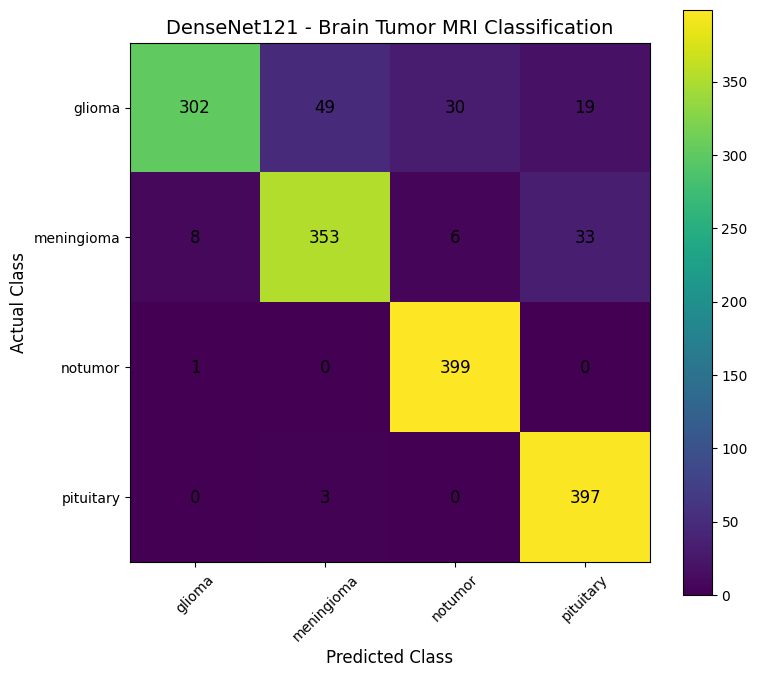


                    PER-CLASS ACCURACY
glioma          : 75.50%
meningioma      : 88.25%
notumor         : 99.75%
pituitary       : 99.25%

                 SAMPLE PREDICTIONS


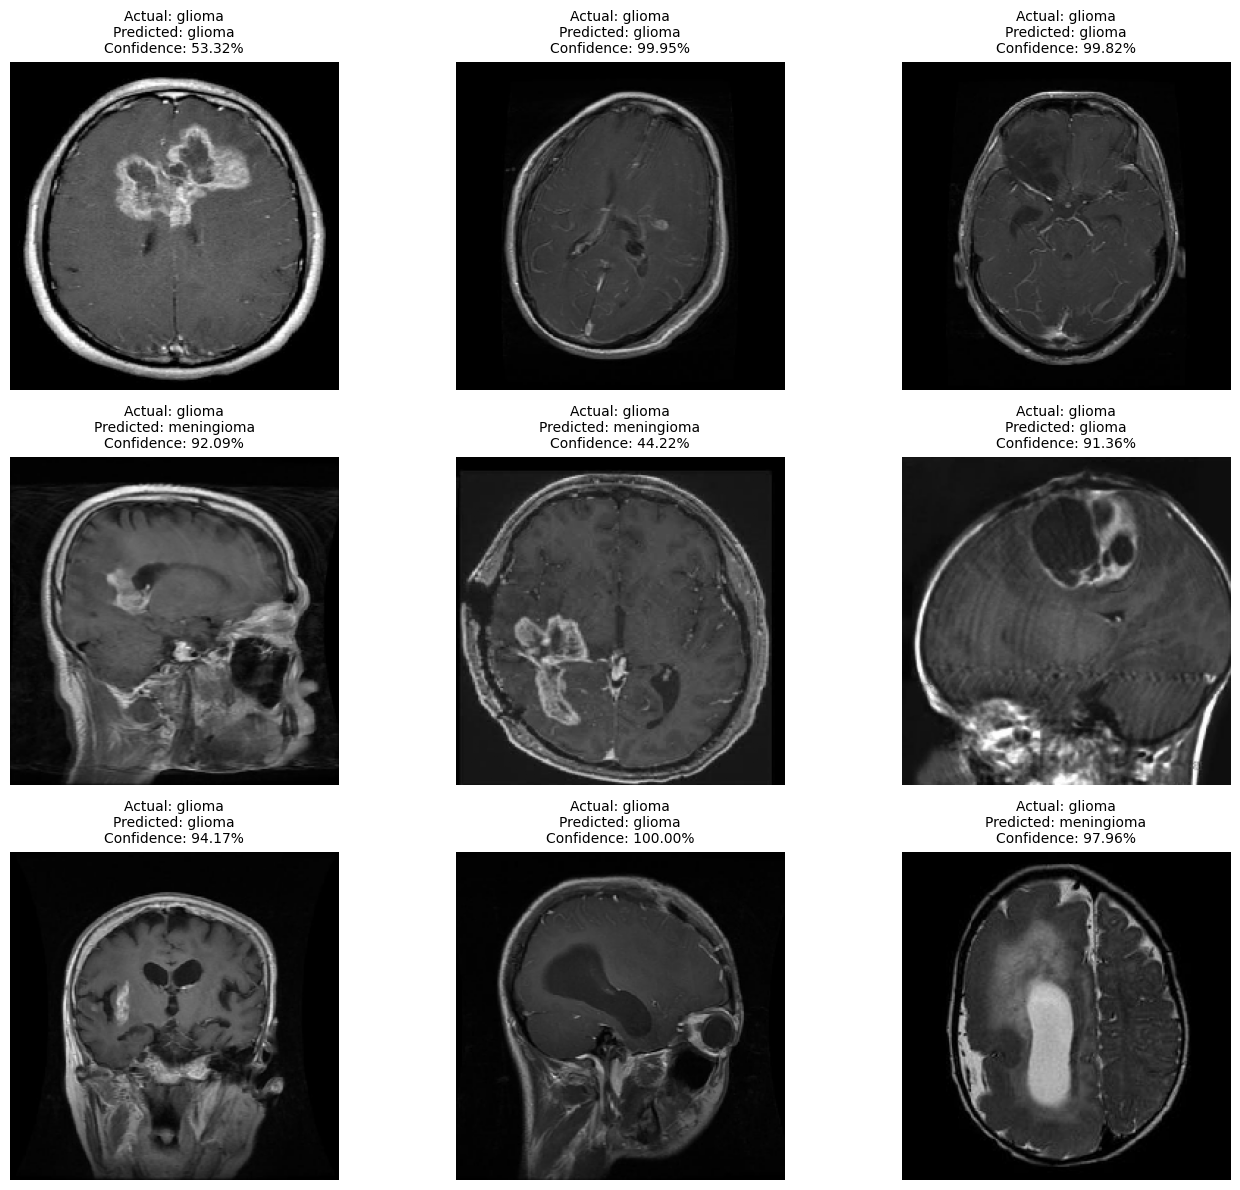


                    FINAL SUMMARY

Model          : DenseNet121
Dataset        : Brain Tumor MRI
Test Images    : 1600
Number Classes : 4

Classes:
1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

Test Accuracy  : 90.69%

MODEL TESTING COMPLETED SUCCESSFULLY


In [6]:
# ============================================================
# MEDOPSAI - DENSENET121 MODEL TESTING
# Brain Tumor MRI Classification
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_PATH = r"C:\Users\ASUS\My_Learning\medical mlops project\models\densenet121_brain_tumor_final.keras"

TEST_DIR = r"C:\Users\ASUS\My_Learning\medical mlops project\dataset\Testing"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# ============================================================
# 2. CHECK PATHS
# ============================================================

print("=" * 70)
print("MEDOPSAI - DENSENET121 MODEL TESTING")
print("=" * 70)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"\nModel not found:\n{MODEL_PATH}"
    )

if not os.path.exists(TEST_DIR):
    raise FileNotFoundError(
        f"\nTesting dataset not found:\n{TEST_DIR}"
    )

print("\nModel path:")
print(MODEL_PATH)

print("\nTesting dataset:")
print(TEST_DIR)

# ============================================================
# 3. LOAD SAVED MODEL
# ============================================================

print("\n" + "-" * 70)
print("Loading saved DenseNet121 model...")
print("-" * 70)

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")

# Display model information
print("\nModel input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

# ============================================================
# 4. CREATE TEST DATA GENERATOR
# ============================================================

print("\n" + "-" * 70)
print("Loading testing dataset...")
print("-" * 70)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("\nTesting dataset loaded successfully!")

print("Total test images :", test_generator.samples)
print("Class mapping     :", test_generator.class_indices)

# ============================================================
# 5. RUN MODEL PREDICTIONS
# ============================================================

print("\n" + "-" * 70)
print("Running predictions...")
print("-" * 70)

# Important: reset generator before prediction
test_generator.reset()

predictions = model.predict(
    test_generator,
    verbose=1
)

# ============================================================
# 6. GET ACTUAL AND PREDICTED LABELS
# ============================================================

# Actual class labels
y_true = test_generator.classes

# Predicted class labels
y_pred = np.argmax(predictions, axis=1)

print("\nPrediction completed!")

print("Number of actual labels    :", len(y_true))
print("Number of predicted labels :", len(y_pred))

# ============================================================
# 7. CALCULATE TEST ACCURACY
# ============================================================

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("                    TEST RESULTS")
print("=" * 70)

print(f"\nTest Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# ============================================================
# 8. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("                 CLASSIFICATION REPORT")
print("=" * 70)

report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
)

print(report)

# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("=" * 70)
print("                    CONFUSION MATRIX")
print("=" * 70)

print("\nRows    = Actual Class")
print("Columns = Predicted Class\n")

print(cm)

# ============================================================
# 10. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(8, 7))

plt.imshow(cm)

plt.title(
    "DenseNet121 - Brain Tumor MRI Classification",
    fontsize=14
)

plt.xlabel(
    "Predicted Class",
    fontsize=12
)

plt.ylabel(
    "Actual Class",
    fontsize=12
)

plt.xticks(
    range(len(CLASS_NAMES)),
    CLASS_NAMES,
    rotation=45
)

plt.yticks(
    range(len(CLASS_NAMES)),
    CLASS_NAMES
)

# Display values inside matrix
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=12
        )

plt.colorbar()

plt.tight_layout()

plt.show()

# ============================================================
# 11. PER-CLASS ACCURACY
# ============================================================

print("\n" + "=" * 70)
print("                    PER-CLASS ACCURACY")
print("=" * 70)

for i, class_name in enumerate(CLASS_NAMES):

    total_actual = np.sum(cm[i])

    correct_predictions = cm[i, i]

    class_accuracy = (
        correct_predictions / total_actual
    ) * 100

    print(
        f"{class_name:<15} : "
        f"{class_accuracy:.2f}%"
    )

# ============================================================
# 12. DISPLAY SAMPLE PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("                 SAMPLE PREDICTIONS")
print("=" * 70)

# Reset generator
test_generator.reset()

# Get one batch
images, labels = next(test_generator)

# Predict batch
batch_predictions = model.predict(
    images,
    verbose=0
)

predicted_classes = np.argmax(
    batch_predictions,
    axis=1
)

actual_classes = np.argmax(
    labels,
    axis=1
)

# Display first 9 images
num_images = min(9, len(images))

plt.figure(figsize=(14, 12))

for i in range(num_images):

    plt.subplot(3, 3, i + 1)

    # Display image
    plt.imshow(images[i])

    actual_name = CLASS_NAMES[
        actual_classes[i]
    ]

    predicted_name = CLASS_NAMES[
        predicted_classes[i]
    ]

    confidence = (
        np.max(batch_predictions[i]) * 100
    )

    plt.title(
        f"Actual: {actual_name}\n"
        f"Predicted: {predicted_name}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=10
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("                    FINAL SUMMARY")
print("=" * 70)

print(f"""
Model          : DenseNet121
Dataset        : Brain Tumor MRI
Test Images    : {len(y_true)}
Number Classes : {len(CLASS_NAMES)}

Classes:
1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

Test Accuracy  : {test_accuracy * 100:.2f}%
""")

print("=" * 70)
print("MODEL TESTING COMPLETED SUCCESSFULLY")
print("=" * 70)

In [10]:
import os

# ============================================================
# MEDOPSAI PROJECT STRUCTURE
# ============================================================

PROJECT_DIR = r"C:\Users\ASUS\My_Learning\medical mlops project"

# ------------------------------------------------------------
# 1. FOLDERS
# ------------------------------------------------------------

folders = [
    "models",

    "dataset",
    "dataset/Training",
    "dataset/Testing",
    "dataset/split_dataset",
    "dataset/split_dataset/train",
    "dataset/split_dataset/validation",
    "dataset/split_dataset/test",

    "mlflow_artifacts",
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Created:", path)


# ------------------------------------------------------------
# 2. FILES
# ------------------------------------------------------------

files = [
    "app.py",
    "train.py",
    "mlflow_tracking.py",
    "requirements.txt",
    "README.md",
    ".gitignore",
]

for filename in files:
    path = os.path.join(PROJECT_DIR, filename)

    if not os.path.exists(path):
        open(path, "w", encoding="utf-8").close()
        print("Created:", path)
    else:
        print("Already exists:", path)


# ------------------------------------------------------------
# 3. .gitignore
# ------------------------------------------------------------

gitignore = [
    "# Python",
    "__pycache__/",
    "*.py[cod]",
    "*.pyo",
    "",
    "# Virtual environments",
    "venv/",
    ".venv/",
    "env/",
    "",
    "# Jupyter",
    ".ipynb_checkpoints/",
    "",
    "# MLflow",
    "mlruns/",
    "mlflow_artifacts/",
    "",
    "# Dataset",
    "dataset/",
    "",
    "# Large model files",
    "*.h5",
    "*.keras",
    "*.ckpt",
    "*.pth",
    "*.pt",
    "",
    "# Generated files",
    "*.png",
    "*.jpg",
    "*.jpeg",
    "",
    "# TensorFlow",
    "checkpoint/",
    "",
    "# IDE",
    ".vscode/",
    ".idea/",
    "",
    "# OS",
    ".DS_Store",
    "Thumbs.db",
]

with open(
    os.path.join(PROJECT_DIR, ".gitignore"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(gitignore))

print("Updated .gitignore")


# ------------------------------------------------------------
# 4. requirements.txt
# ------------------------------------------------------------

requirements = [
    "tensorflow",
    "numpy",
    "pandas",
    "pillow",
    "scikit-learn",
    "matplotlib",
    "streamlit",
    "mlflow",
]

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(requirements))

print("Updated requirements.txt")


# ------------------------------------------------------------
# 5. README.md
# ------------------------------------------------------------

readme_lines = [
    "# MedOpsAI",
    "",
    "## Brain Tumor MRI Classification and MLOps Platform",
    "",
    "MedOpsAI is a deep learning and MLOps project for classifying brain MRI images into four categories:",
    "",
    "- Glioma",
    "- Meningioma",
    "- No Tumor",
    "- Pituitary",
    "",
    "## Model",
    "",
    "DenseNet121 with transfer learning and fine-tuning.",
    "",
    "## MLOps Components",
    "",
    "- Git / GitHub",
    "- MLflow",
    "- Streamlit",
    "- Model Evaluation",
    "- Model Management",
    "- Monitoring",
    "- Retraining",
    "",
    "## Model Performance",
    "",
    "Test Accuracy: 90.69%",
    "",
    "## Web Application",
    "",
    "The trained model is deployed through Streamlit.",
]

with open(
    os.path.join(PROJECT_DIR, "README.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(readme_lines))

print("Updated README.md")


# ------------------------------------------------------------
# 6. FINAL STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MEDOPSAI PROJECT STRUCTURE CREATED")
print("=" * 60)

print("""
medical mlops project/
│
├── app.py
├── train.py
├── mlflow_tracking.py
├── requirements.txt
├── README.md
├── .gitignore
│
├── models/
│   └── densenet121_brain_tumor_final.keras
│
├── dataset/
│   ├── Training/
│   ├── Testing/
│   └── split_dataset/
│       ├── train/
│       ├── validation/
│       └── test/
│
└── mlflow_artifacts/
""")

print("Done!")

Created: C:\Users\ASUS\My_Learning\medical mlops project\models
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/Training
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/Testing
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/split_dataset
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/split_dataset/train
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/split_dataset/validation
Created: C:\Users\ASUS\My_Learning\medical mlops project\dataset/split_dataset/test
Created: C:\Users\ASUS\My_Learning\medical mlops project\mlflow_artifacts
Already exists: C:\Users\ASUS\My_Learning\medical mlops project\app.py
Created: C:\Users\ASUS\My_Learning\medical mlops project\train.py
Created: C:\Users\ASUS\My_Learning\medical mlops project\mlflow_tracking.py
Created: C:\Users\ASUS\My_Learning\medical mlops project\requirements.txt
Created: C:\Users\ASUS\My